# Import libraries

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.feature_selection import SelectFromModel

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Step 2: Load dataset

In [10]:
df = pd.read_csv(r"C:\Users\hp\OneDrive\Desktop\MLA\Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# Step 3: EDA

In [11]:
# Shape
print("Shape:", df.shape)

# Information
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate values
print("\nDuplicates:", df.duplicated().sum())

# Statistical summary
df.describe()

# Target variable distribution
print("\nAttrition Count:")
print(df['Attrition'].value_counts())

# Target variable percentage
print("\nAttrition Percentage:")
print(df['Attrition'].value_counts(normalize=True) * 100
)

Shape: (1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLev

In [12]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


# Visualize class imbalance

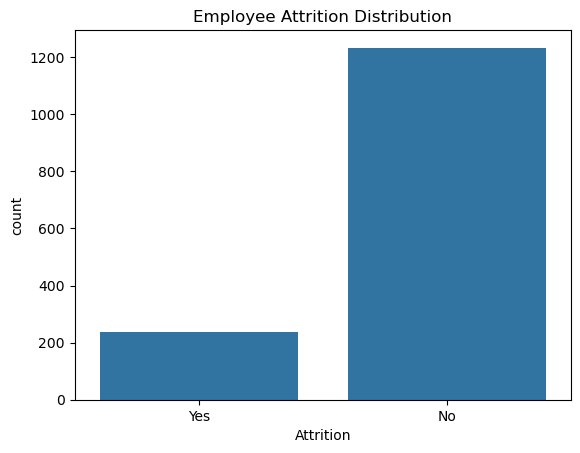

In [13]:
sns.countplot(data=df, x='Attrition')

plt.title("Employee Attrition Distribution")
plt.show()

# Step 4: Remove unnecessary columns

In [14]:
df.drop(
    columns=[
        'EmployeeNumber',
        'EmployeeCount',
        'Over18',
        'StandardHours'
    ],
    inplace=True,
    errors='ignore'
)

df.shape

(1470, 31)

# Step 5: Separate X and y

In [15]:
X = df.drop('Attrition', axis=1)

y = df['Attrition'].map({
    'No': 0,
    'Yes': 1
})

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (1470, 30)
y Shape: (1470,)


# Step 6: Train-test split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1176, 30)
X_test: (294, 30)
y_train: (1176,)
y_test: (294,)


# Check class imbalance before oversampling

In [17]:
print("Before Oversampling:")
print(y_train.value_counts())

Before Oversampling:
Attrition
0    986
1    190
Name: count, dtype: int64


# Step 7: Identify categorical and numerical columns

In [18]:
cat_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

num_cols = X_train.select_dtypes(
    include='number'
).columns.tolist()

print("Categorical Columns:")
print(cat_cols)

print("\nNumerical Columns:")
print(num_cols)

Categorical Columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical Columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


# Step 8: One-Hot Encoding

In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            cat_cols
        ),
        (
            'num',
            'passthrough',
            num_cols
        )
    ]
)

# Step 9: Build the Decision Tree with Oversampling and Feature Selection
# Main model pipeline
# This pipeline will perform these operations in order:
# 1. Random Oversampling
# 2. Feature Selection
# 3. Decision Tree Classification

In [20]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),

    ('oversampler', RandomOverSampler(
        random_state=42
    )),

    ('feature_selection', SelectFromModel(
        estimator=DecisionTreeClassifier(
            max_depth=3,
            random_state=42
        ),
        threshold='median'
    )),

    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_split=50,
        min_samples_leaf=10,
        random_state=42
    ))
])

# Step 10: Train the model

In [21]:
dt_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('oversampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


# Step 11: Make predictions

In [22]:
pred_train = dt_model.predict(X_train)

pred_test = dt_model.predict(X_test)

In [23]:
pred_train

array([0, 0, 0, ..., 0, 0, 0], shape=(1176,))

In [24]:
pred_test

array([1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0])

# Step 12: Training and Testing Accuracy

In [25]:
acc_train = accuracy_score(
    y_train,
    pred_train
)

acc_test = accuracy_score(
    y_test,
    pred_test
)

print("Training Accuracy:", acc_train * 100, "%")

print("Testing Accuracy:", acc_test * 100, "%")

Training Accuracy: 79.76190476190477 %
Testing Accuracy: 70.06802721088435 %


# Step 13: Check overfitting

In [26]:
train_f1 = f1_score(y_train, pred_train)

test_f1 = f1_score(y_test, pred_test)

train_recall = recall_score(y_train, pred_train)

test_recall = recall_score(y_test, pred_test)

print("Training F1:", train_f1)

print("Testing F1:", test_f1)

print("Training Recall:", train_recall)

print("Testing Recall:", test_recall)

Training F1: 0.5423076923076923
Testing F1: 0.3333333333333333
Training Recall: 0.7421052631578947
Testing Recall: 0.46808510638297873


In [27]:
# If training metrics are significantly higher than testing metrics, that can indicate overfitting.

# Step 14: Classification Report

In [28]:
print(classification_report(
    y_test,
    pred_test,
    target_names=['No Attrition', 'Attrition'],
    zero_division=0
))

              precision    recall  f1-score   support

No Attrition       0.88      0.74      0.81       247
   Attrition       0.26      0.47      0.33        47

    accuracy                           0.70       294
   macro avg       0.57      0.61      0.57       294
weighted avg       0.78      0.70      0.73       294



# Step 15: Confusion Matrix

In [29]:
cm = confusion_matrix(
    y_test,
    pred_test,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=['Actual No', 'Actual Yes'],
    columns=['Predicted No', 'Predicted Yes']
)

print(cm_df)

            Predicted No  Predicted Yes
Actual No            184             63
Actual Yes            25             22


# Visualize it:

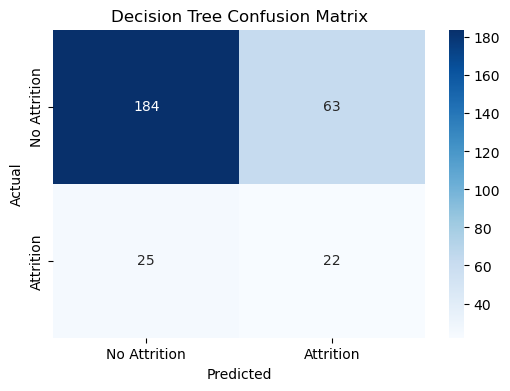

In [30]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Attrition', 'Attrition'],
    yticklabels=['No Attrition', 'Attrition']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Decision Tree Confusion Matrix")

plt.show()

# Step 16: Calculate ROC-AUC

In [31]:
pred_prob_test = dt_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    pred_prob_test
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.6736583685071926


# Step 17: Calculate Balanced Accuracy

In [32]:
bal_acc = balanced_accuracy_score(
    y_test,
    pred_test
)

print("Balanced Accuracy:", bal_acc)

Balanced Accuracy: 0.6065121888190197


# Step 18: Feature Importance

In [33]:
# Get the trained classifier
tree_model = dt_model.named_steps['classifier']

# Get all encoded feature names
all_feature_names = (
    dt_model.named_steps['preprocessor']
    .get_feature_names_out()
)

# Get features selected by SelectFromModel
selected_mask = (
    dt_model.named_steps['feature_selection']
    .get_support()
)

selected_feature_names = all_feature_names[selected_mask]

# Get feature importance
importance = tree_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': selected_feature_names,
    'Importance': importance
})

# Sort
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                                   Feature  Importance
44                  num__TotalWorkingYears    0.208706
26                        cat__OverTime_No    0.178082
28                                num__Age    0.160879
43                   num__StockOptionLevel    0.083604
39                 num__NumCompaniesWorked    0.081944
30                   num__DistanceFromHome    0.068904
46                    num__WorkLifeBalance    0.065021
29                          num__DailyRate    0.045285
48                 num__YearsInCurrentRole    0.029397
49            num__YearsSinceLastPromotion    0.027990
20         cat__JobRole_Research Scientist    0.024345
32            num__EnvironmentSatisfaction    0.017809
23             cat__MaritalStatus_Divorced    0.005870
50               num__YearsWithCurrManager    0.002164
37                      num__MonthlyIncome    0.000000
36                    num__JobSatisfaction    0.000000
35                           num__JobLevel    0.000000
34        

# Visualize feature importance

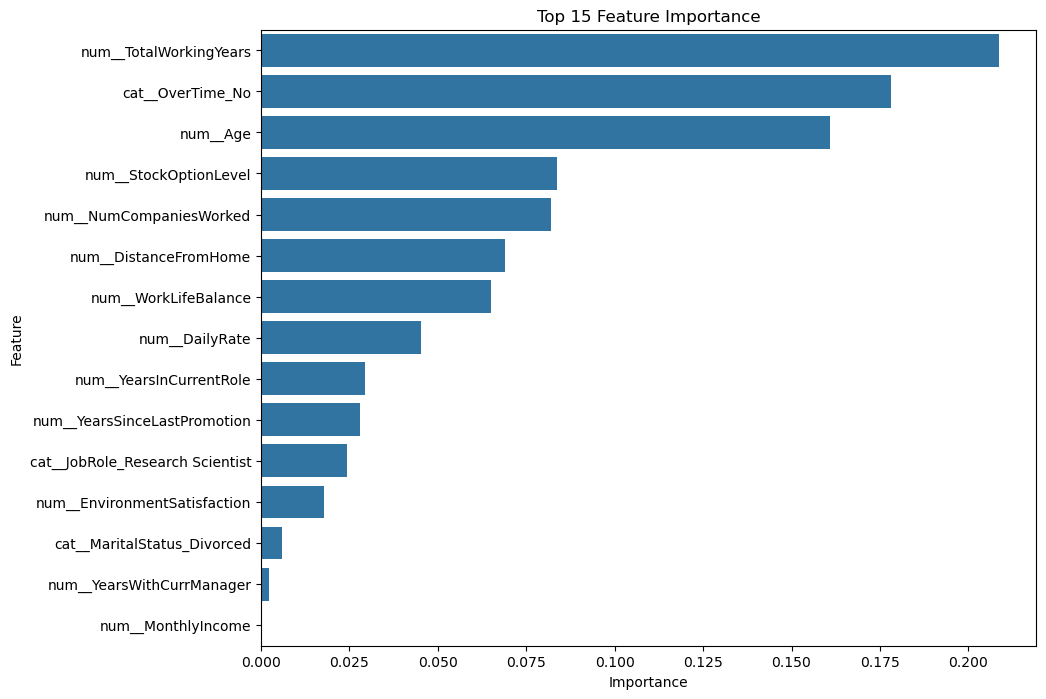

In [34]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Feature Importance")

plt.show()

# Step 19: GridSearchCV — Hyperparameter Tuning
# Now we will find the best Decision Tree parameters.

In [35]:
param_grid = {
    'classifier__criterion': ['gini', 'entropy'],

    'classifier__max_depth': [3, 4, 5, 6, 7, 8, 10],

    'classifier__min_samples_split': [20, 50, 75, 100],

    'classifier__min_samples_leaf': [5, 10, 20]
}

# Apply GridSearchCV

In [36]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [3, 4, ...], 'classifier__min_samples_leaf': [5, 10, ...], 'classifier__min_samples_split': [20, 50, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('cat', ...), ('num', ...)]"


# Find best parameters

In [37]:
print("Best Parameters:")
print(grid.best_params_)

print("\nBest CV F1 Score:")
print(grid.best_score_)

Best Parameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 20}

Best CV F1 Score:
0.45632526655657946


# Step 20: Evaluate the best model

In [38]:
best_model = grid.best_estimator_

best_pred_train = best_model.predict(X_train)

best_pred_test = best_model.predict(X_test)

print("Best Model Training Accuracy:",
      accuracy_score(y_train, best_pred_train))

print("Best Model Testing Accuracy:",
      accuracy_score(y_test, best_pred_test))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred_test,
    target_names=['No Attrition', 'Attrition'],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, best_pred_test))

print("\nROC-AUC:")
print(roc_auc_score(
    y_test,
    best_model.predict_proba(X_test)[:, 1]
))

Best Model Training Accuracy: 0.8460884353741497
Best Model Testing Accuracy: 0.7448979591836735

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.87      0.82      0.84       247
   Attrition       0.27      0.34      0.30        47

    accuracy                           0.74       294
   macro avg       0.57      0.58      0.57       294
weighted avg       0.77      0.74      0.76       294


Confusion Matrix:
[[203  44]
 [ 31  16]]

ROC-AUC:
0.5970798518390904


# Step 21: Visualize the final Decision Tree

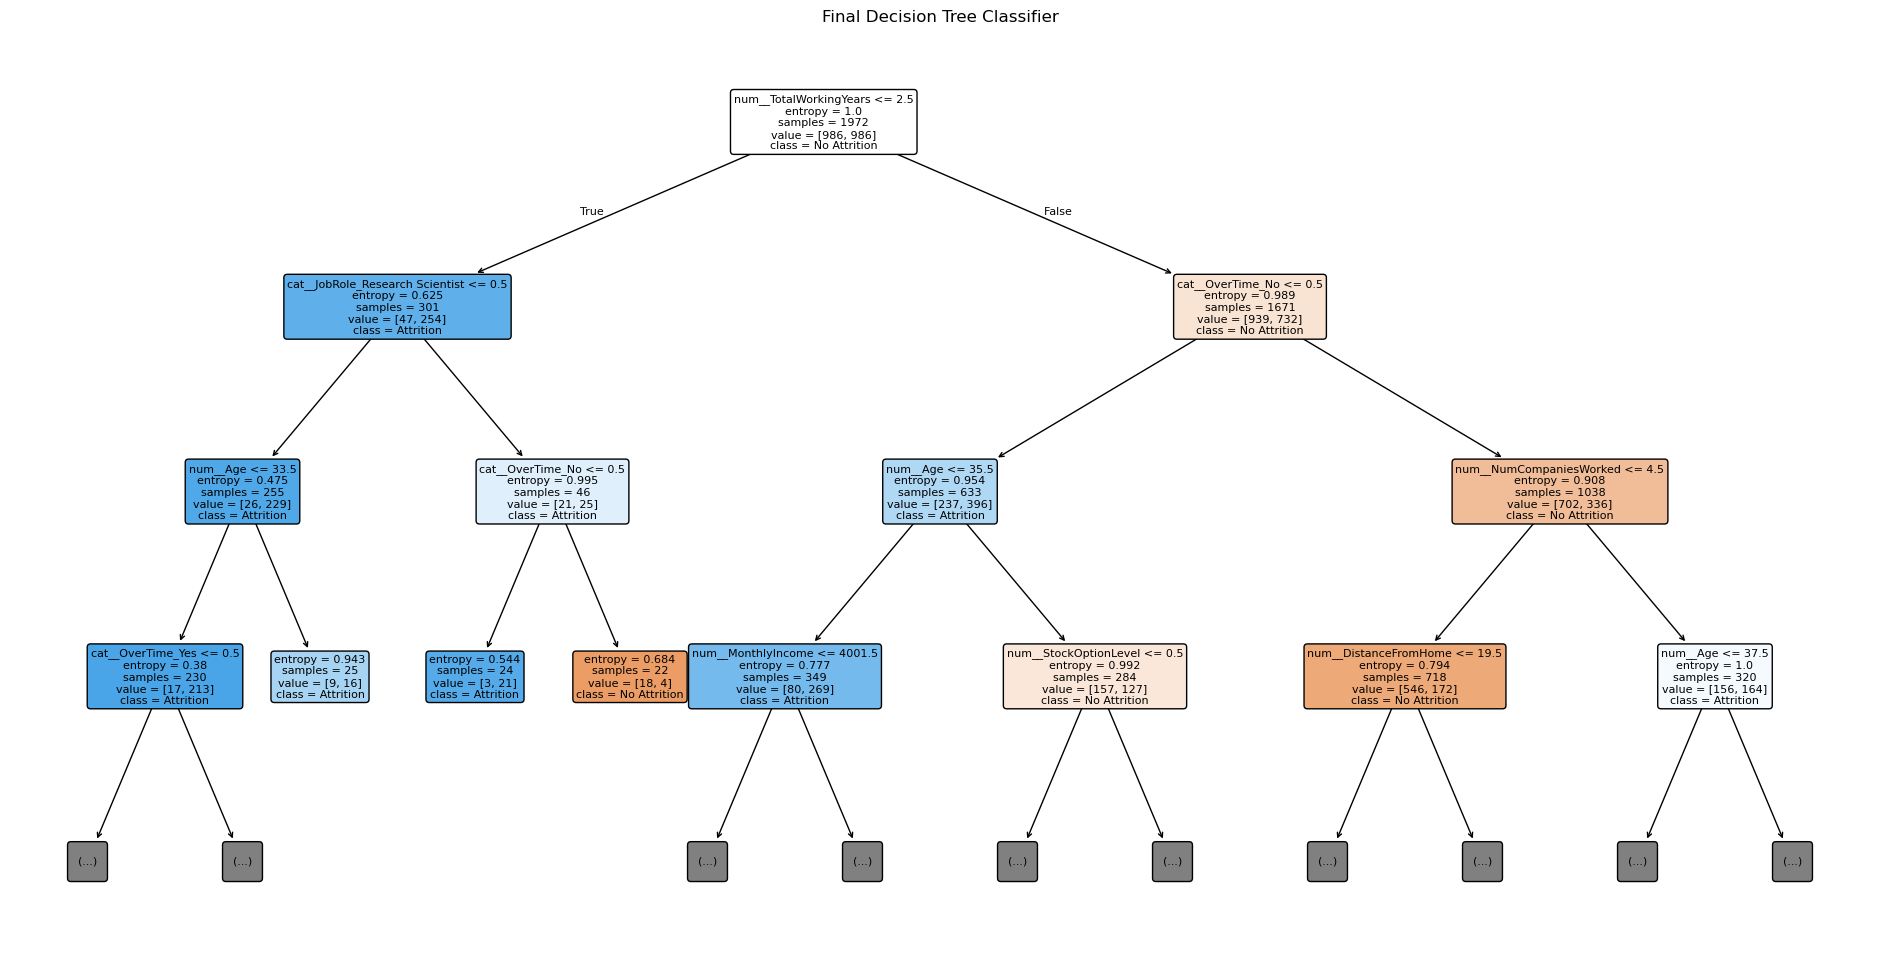

In [39]:
# Extract final classifier
final_tree = best_model.named_steps['classifier']

# Get feature names after preprocessing
all_feature_names = (
    best_model.named_steps['preprocessor']
    .get_feature_names_out()
)

# Get selected feature names
selected_mask = (
    best_model.named_steps['feature_selection']
    .get_support()
)

final_feature_names = all_feature_names[selected_mask]

plt.figure(figsize=(24, 12))

plot_tree(
    final_tree,
    feature_names=final_feature_names,
    class_names=['No Attrition', 'Attrition'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Final Decision Tree Classifier")

plt.show()

# Step 22: Final Model Performance Summary

In [41]:
results = pd.DataFrame({
    'Metric': [
        'Training Accuracy',
        'Testing Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC',
        'Balanced Accuracy'
    ],

    'Score': [
        accuracy_score(y_train, best_pred_train),
        accuracy_score(y_test, best_pred_test),
        precision_score(y_test, best_pred_test, zero_division=0),
        recall_score(y_test, best_pred_test, zero_division=0),
        f1_score(y_test, best_pred_test, zero_division=0),
        roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]),
        balanced_accuracy_score(y_test, best_pred_test)
    ]
})

print(results)

              Metric     Score
0  Training Accuracy  0.846088
1   Testing Accuracy  0.744898
2          Precision  0.266667
3             Recall  0.340426
4           F1 Score  0.299065
5            ROC-AUC  0.597080
6  Balanced Accuracy  0.581144
